In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Configure Plot Aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Google Sheets ID and Export URL
SPREADSHEET_ID = "1sPmmnv19xEr7SlP1lRj-3YAW2vkSLOv3izE-QuIo12Y"
EXPORT_URL = f"https://docs.google.com/spreadsheets/d/{SPREADSHEET_ID}/export?format=xlsx"

print("Loading dataset from Google Sheets...")
xls = pd.ExcelFile(EXPORT_URL)
print(f"Sheets found: {xls.sheet_names}\n")

all_dfs = []

for sheet_name in xls.sheet_names:
    df_sheet = pd.read_excel(xls, sheet_name=sheet_name)

    # Standardize column names
    col_map = {}
    for col in df_sheet.columns:
        col_lower = str(col).strip().lower()
        if col_lower in ['soal']:
            col_map[col] = 'soal'
        elif col_lower in ['kunci jawaban', 'kunci_jawaban']:
            col_map[col] = 'kunci_jawaban'
        elif col_lower in ['jawaban', 'jawaban siswa', 'jawaban_siswa']:
            col_map[col] = 'jawaban_siswa'
        elif col_lower in ['nilai', 'skor']:
            col_map[col] = 'nilai'

    df_sheet = df_sheet.rename(columns=col_map)

    # Forward fill merged cells for 'soal' and 'kunci_jawaban'
    if 'soal' in df_sheet.columns:
        df_sheet['soal'] = df_sheet['soal'].ffill()
    if 'kunci_jawaban' in df_sheet.columns:
        df_sheet['kunci_jawaban'] = df_sheet['kunci_jawaban'].ffill()

    df_sheet['mata_pelajaran'] = sheet_name
    all_dfs.append(df_sheet)

# Concatenate all sheets into a single dataframe
df = pd.concat(all_dfs, ignore_index=True)

# Initial data cleaning for essential columns
df = df.dropna(subset=['jawaban_siswa', 'nilai']).copy()
df['nilai'] = pd.to_numeric(df['nilai'], errors='coerce')
df = df.dropna(subset=['nilai'])

print("=== RAW DATASET SUMMARY ===")
print(f"Total Rows: {len(df)}")
print(f"Number of Unique Subjects: {df['mata_pelajaran'].nunique()}")
print(df.head())

Loading dataset from Google Sheets...
Sheets found: ['Bahasa Indonesia-7_Yasmin', 'Bahasa Indonesia-12_Zahra', 'Sejarah-11_Khoir', 'Seni Budaya-10-12_Lutfi', 'PKN-7-8-10-11-12_Harits']

=== RAW DATASET SUMMARY ===
Total Rows: 10518
Number of Unique Subjects: 5
                                     soal  \
0  Apa yang dimaksud dengan puisi rakyat?   
1  Apa yang dimaksud dengan puisi rakyat?   
2  Apa yang dimaksud dengan puisi rakyat?   
3  Apa yang dimaksud dengan puisi rakyat?   
4  Apa yang dimaksud dengan puisi rakyat?   

                                       kunci_jawaban  \
0  Puisi rakyat adalah karya sastra yang berkemba...   
1  Puisi rakyat adalah karya sastra yang berkemba...   
2  Puisi rakyat adalah karya sastra yang berkemba...   
3  Puisi rakyat adalah karya sastra yang berkemba...   
4  Puisi rakyat adalah karya sastra yang berkemba...   

                                       jawaban_siswa  nilai  \
0  Sastra lisan berupa puisi terikat yang berkemb...    9.0   
1  ad

## 2. PEMBERSIHAN DATA (DATA CLEANING)
Pada tahap ini kita akan membersihkan dataset dari duplikat dan jawaban anomali sebelum lanjut ke tahap analisis EDA visual.

In [ ]:
import pandas as pd

if 'df' not in globals():
    print("[ERROR] Variabel 'df' belum ditemukan. Silakan jalankan sel inisialisasi/import dataset di bagian paling atas terlebih dahulu!")
else:
    # 1. Salin dataframe awal
    df_analysis = df.copy()
    initial_len = len(df_analysis)

    # Pastikan kolom jumlah kata tersedia
    if 'len_jawaban_word' not in df_analysis.columns:
        df_analysis['len_jawaban_word'] = df_analysis['jawaban_siswa'].apply(lambda x: len(str(x).split()) if pd.notna(x) else 0)

    # 2. Identifikasi & Hapus Duplikat
    duplicate_count = df_analysis.duplicated(subset=['jawaban_siswa']).sum()
    df_clean = df_analysis.drop_duplicates(subset=['jawaban_siswa'], keep='first').copy()

    # 3. Identifikasi & Hapus Anomali (<= 2 kata)
    anomaly_count = len(df_clean[df_clean['len_jawaban_word'] <= 2])
    df_clean = df_clean[df_clean['len_jawaban_word'] > 2].copy()

    print("=== LAPORAN PEMBERSIHAN DATA ===")
    print(f"Total Baris Awal           : {initial_len}")
    print(f"Jumlah Baris Duplikat      : {duplicate_count}")
    print(f"Jumlah Baris Anomali (<=2) : {anomaly_count}")
    print(f"Total Baris Setelah Clean  : {len(df_clean)}")
    print(f"Data Terbuang              : {initial_len - len(df_clean)} baris ({((initial_len - len(df_clean))/initial_len)*100:.2f}%)")

=== LAPORAN PEMBERSIHAN DATA ===
Total Baris Awal           : 10518
Jumlah Baris Duplikat      : 1589
Jumlah Baris Anomali (<=2) : 227
Total Baris Setelah Clean  : 8702
Data Terbuang              : 1816 baris (17.27%)


# 3 Statistik Deskriptif Dataset Bersih
Di bawah ini adalah ringkasan statistik deskriptif dari seluruh data yang telah dibersihkan (`df_clean`), baik secara keseluruhan maupun dikelompokkan berdasarkan mata pelajaran.


In [ ]:
import pandas as pd

if 'df_clean' in globals():
    # 1. Statistik Deskriptif Umum (Numerik)
    print("=== 1. STATISTIK DESKRIPTIF UMUM (NUMERIK) ===")
    umum_desc = df_clean[['nilai', 'len_jawaban_word', 'cosine_similarity']].describe().transpose()
    # Tambahkan median secara manual
    umum_desc['median'] = [df_clean['nilai'].median(), df_clean['len_jawaban_word'].median(), df_clean['cosine_similarity'].median()]
    # Atur urutan kolom
    umum_desc = umum_desc[['count', 'mean', 'median', 'std', 'min', '25%', '75%', 'max']]
    print(umum_desc.round(4).to_string())

    # 2. Statistik Deskriptif per Mata Pelajaran
    print("\n=== 2. STATISTIK DESKRIPTIF PER MATA PELAJARAN ===")
    subject_desc = df_clean.groupby('mata_pelajaran').agg(
        jumlah_siswa=('nilai', 'count'),
        rata_rata_nilai=('nilai', 'mean'),
        median_nilai=('nilai', 'median'),
        std_nilai=('nilai', 'std'),
        rata_rata_kata=('len_jawaban_word', 'mean'),
        rata_rata_kemiripan=('cosine_similarity', 'mean')
    ).sort_values(by='rata_rata_nilai', ascending=False)

    print(subject_desc.round(4).to_string())

    # 3. Statistik Deskriptif Data Kategorikal
    print("\n=== 3. STATISTIK DATA KATEGORIKAL ===")
    kategori_desc = df_clean[['mata_pelajaran', 'kategori_nilai']].describe(include=['O']).transpose()
    print(kategori_desc.to_string())
else:
    print("[ERROR] Variabel 'df_clean' tidak ditemukan. Pastikan proses pembersihan data sudah dijalankan!")

=== 1. STATISTIK DESKRIPTIF UMUM (NUMERIK) ===
                    count     mean   median      std  min     25%      75%    max
nilai              8702.0   6.2528   7.0000   3.1613  0.0  4.0000   9.0000   10.0
len_jawaban_word   8702.0  16.7741  14.0000  11.8804  3.0  9.0000  21.0000  145.0
cosine_similarity  8702.0   0.2310   0.1905   0.1864  0.0  0.0861   0.3361    1.0

=== 2. STATISTIK DESKRIPTIF PER MATA PELAJARAN ===
                           jumlah_siswa  rata_rata_nilai  median_nilai  std_nilai  rata_rata_kata  rata_rata_kemiripan
mata_pelajaran                                                                                                        
Bahasa Indonesia-12_Zahra          1855           7.4447           8.0     2.0715         17.0275               0.2794
PKN-7-8-10-11-12_Harits            1559           7.0244           8.0     2.9280         22.6254               0.2407
Sejarah-11_Khoir                   1947           6.8356           7.0     2.5506         18.5763

## 4. ANALISIS DATA EKSPLORATIF (EDA) - DATA BERSIH
Pada bagian ini, kita melakukan analisis visual terhadap data yang sudah bersih (`df_clean`) untuk memahami karakteristik nilai dan jawaban siswa.

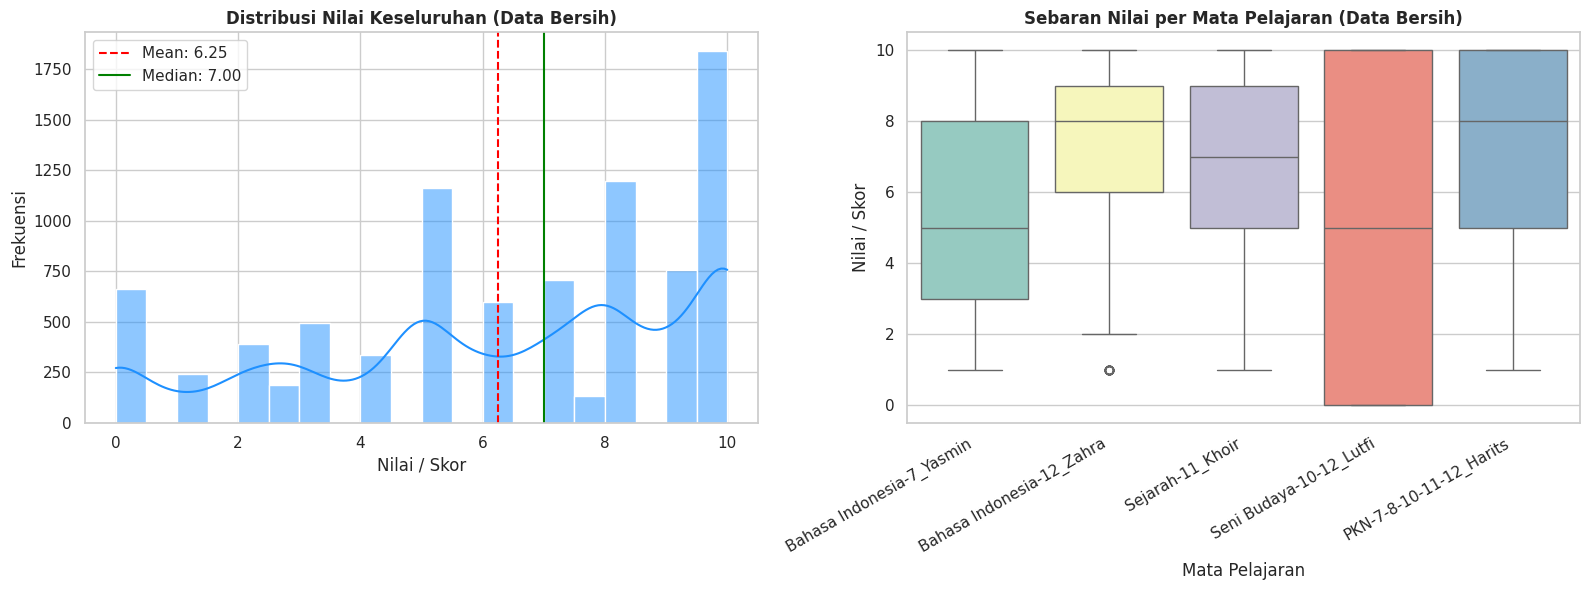

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Memastikan dataset bersih tersedia
if 'df_clean' not in globals():
    print("[ERROR] Variabel 'df_clean' tidak ditemukan. Jalankan sel pembersihan data terlebih dahulu.")
else:
    # Set ukuran figure untuk 2 analisis utama
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # 1. Distribusi Nilai Secara Keseluruhan
    sns.histplot(data=df_clean, x='nilai', kde=True, bins=20, color='dodgerblue', ax=axes[0])
    axes[0].axvline(df_clean['nilai'].mean(), color='red', linestyle='--', label=f"Mean: {df_clean['nilai'].mean():.2f}")
    axes[0].axvline(df_clean['nilai'].median(), color='green', linestyle='-', label=f"Median: {df_clean['nilai'].median():.2f}")
    axes[0].set_title('Distribusi Nilai Keseluruhan (Data Bersih)', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Nilai / Skor')
    axes[0].set_ylabel('Frekuensi')
    axes[0].legend()

    # 2. Distribusi Nilai per Mata Pelajaran
    sns.boxplot(data=df_clean, x='mata_pelajaran', y='nilai', hue='mata_pelajaran', palette='Set3', legend=False, ax=axes[1])
    axes[1].set_title('Sebaran Nilai per Mata Pelajaran (Data Bersih)', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Mata Pelajaran')
    axes[1].set_ylabel('Nilai / Skor')

    # Mengatasi UserWarning dengan menetapkan ticks terlebih dahulu
    unique_subjects = df_clean['mata_pelajaran'].unique()
    axes[1].set_xticks(range(len(unique_subjects)))
    axes[1].set_xticklabels(unique_subjects, rotation=30, ha='right')

    plt.tight_layout()
    plt.show()

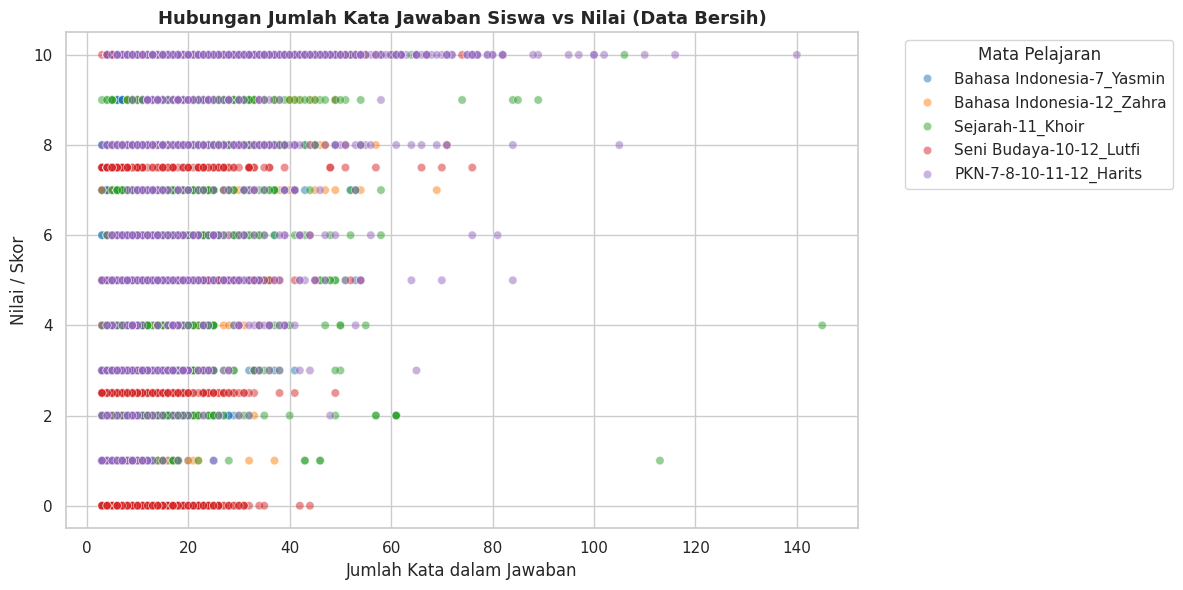

In [ ]:
# 3. Hubungan Jumlah Kata Jawaban dengan Nilai
if 'df_clean' in globals():
    plt.figure(figsize=(12, 6))
    sns.scatterplot(data=df_clean, x='len_jawaban_word', y='nilai', hue='mata_pelajaran', alpha=0.5, palette='tab10')
    plt.title('Hubungan Jumlah Kata Jawaban Siswa vs Nilai (Data Bersih)', fontsize=13, fontweight='bold')
    plt.xlabel('Jumlah Kata dalam Jawaban')
    plt.ylabel('Nilai / Skor')
    plt.legend(title='Mata Pelajaran', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

### 3.1 Analisis Tambahan EDA: Panjang Jawaban & Analisis Kemiripan (Similarity) Awal
Di bawah ini kita akan mengeksplorasi rata-rata jumlah kata tiap mata pelajaran serta menghitung kesamaan tekstual kasar menggunakan TF-IDF dan Cosine Similarity untuk melihat korelasinya dengan nilai.

Menghitung Cosine Similarity menggunakan TF-IDF...


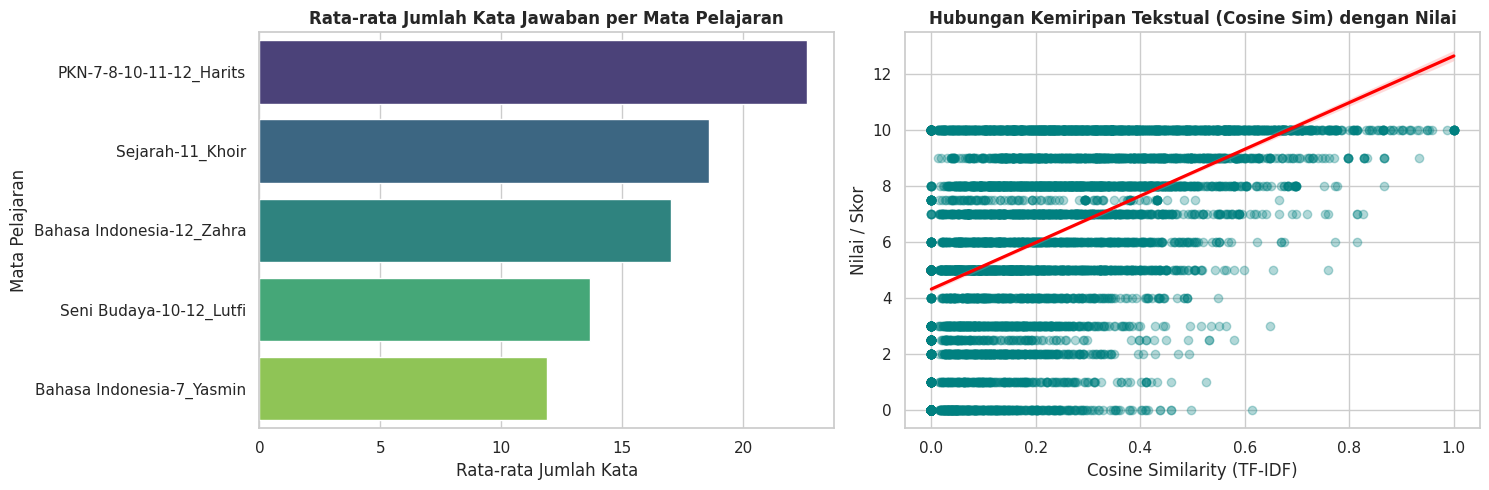


Korelasi Pearson antara Cosine Similarity dan Nilai: 0.4913


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Rata-rata Panjang Jawaban per Mata Pelajaran
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
mean_words = df_clean.groupby('mata_pelajaran')['len_jawaban_word'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=mean_words, x='len_jawaban_word', y='mata_pelajaran', palette='viridis', hue='mata_pelajaran', legend=False)
plt.title('Rata-rata Jumlah Kata Jawaban per Mata Pelajaran', fontsize=12, fontweight='bold')
plt.xlabel('Rata-rata Jumlah Kata')
plt.ylabel('Mata Pelajaran')

# 2. Menghitung Cosine Similarity sederhana antara Jawaban Siswa dan Kunci Jawaban
print("Menghitung Cosine Similarity menggunakan TF-IDF...")
similarities = []

# Kita lakukan loop per baris untuk membandingkan jawaban_siswa dengan kunci_jawaban masing-masing
for idx, row in df_clean.iterrows():
    siswa = str(row['jawaban_siswa'])
    kunci = str(row['kunci_jawaban'])

    try:
        vectorizer = TfidfVectorizer().fit_transform([siswa, kunci])
        vectors = vectorizer.toarray()
        # Hitung cosine similarity antara dokumen 1 (siswa) dan dokumen 2 (kunci)
        sim = cosine_similarity([vectors[0]], [vectors[1]])[0][0]
    except:
        sim = 0.0
    similarities.append(sim)

df_clean['cosine_similarity'] = similarities

# Plot Hubungan Cosine Similarity dengan Nilai
plt.subplot(1, 2, 2)
sns.regplot(data=df_clean, x='cosine_similarity', y='nilai',
            scatter_kws={'alpha': 0.3, 'color': 'teal'}, line_kws={'color': 'red'})
plt.title('Hubungan Kemiripan Tekstual (Cosine Sim) dengan Nilai', fontsize=12, fontweight='bold')
plt.xlabel('Cosine Similarity (TF-IDF)')
plt.ylabel('Nilai / Skor')

plt.tight_layout()
plt.show()

# Menampilkan korelasi Pearson
korelasi = df_clean['cosine_similarity'].corr(df_clean['nilai'])
print(f"\nKorelasi Pearson antara Cosine Similarity dan Nilai: {korelasi:.4f}")


### 3.2 Analisis Distribusi Cosine Similarity berdasarkan Kelompok Nilai
Untuk melihat pola kemiripan jawaban siswa secara lebih intuitif, kita akan membagi nilai siswa menjadi 3 kategori:
- **Rendah** (Skor 0 - 4)
- **Sedang** (Skor 5 - 7)
- **Tinggi** (Skor 8 - 10)

Kemudian kita plot distribusi tingkat kemiripannya (*Cosine Similarity*) menggunakan KDE Plot.

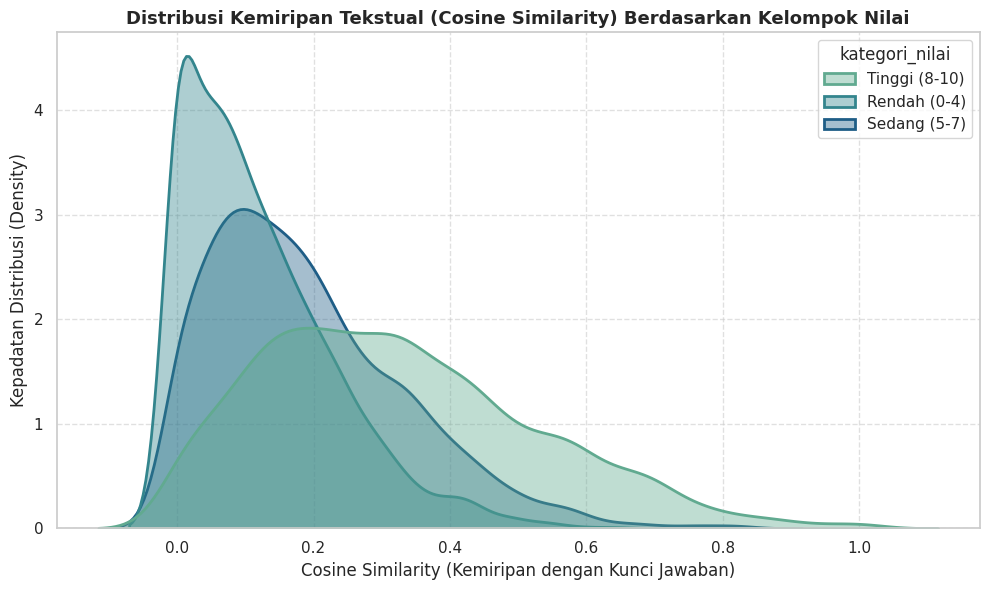

=== STATISTIK KEMIRIPAN TEKSTUAL PER KELOMPOK NILAI ===
                    mean    median       std  count
kategori_nilai                                     
Rendah (0-4)    0.119121  0.093167  0.110138   2313
Sedang (5-7)    0.189967  0.163953  0.142455   2464
Tinggi (8-10)   0.322783  0.298702  0.200819   3925


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if 'df_clean' in globals() and 'cosine_similarity' in df_clean.columns:
    # Buat fungsi pengelompokan nilai
    def kelompokkan_nilai(nilai):
        if nilai <= 4:
            return 'Rendah (0-4)'
        elif nilai <= 7:
            return 'Sedang (5-7)'
        else:
            return 'Tinggi (8-10)'

    # Terapkan pengelompokan
    df_clean['kategori_nilai'] = df_clean['nilai'].apply(kelompokkan_nilai)

    # Plot KDE
    plt.figure(figsize=(10, 6))
    sns.kdeplot(data=df_clean, x='cosine_similarity', hue='kategori_nilai',
                fill=True, common_norm=False, palette='crest', alpha=0.4, linewidth=2)

    plt.title('Distribusi Kemiripan Tekstual (Cosine Similarity) Berdasarkan Kelompok Nilai', fontsize=13, fontweight='bold')
    plt.xlabel('Cosine Similarity (Kemiripan dengan Kunci Jawaban)')
    plt.ylabel('Kepadatan Distribusi (Density)')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

    # Tampilkan statistik deskriptif rata-rata kemiripan per kelompok
    summary_stats = df_clean.groupby('kategori_nilai')['cosine_similarity'].agg(['mean', 'median', 'std', 'count'])
    print("=== STATISTIK KEMIRIPAN TEKSTUAL PER KELOMPOK NILAI ===")
    print(summary_stats.to_string())
else:
    print("[ERROR] Kolom 'cosine_similarity' belum dihitung. Pastikan menjalankan sel EDA sebelumnya terlebih dahulu!")

### 3.3 Matriks Korelasi antar Fitur Numerik
Bagian ini memvisualisasikan korelasi antar variabel numerik (`nilai`, `len_jawaban_word`, dan `cosine_similarity`) menggunakan heatmap korelasi Pearson.

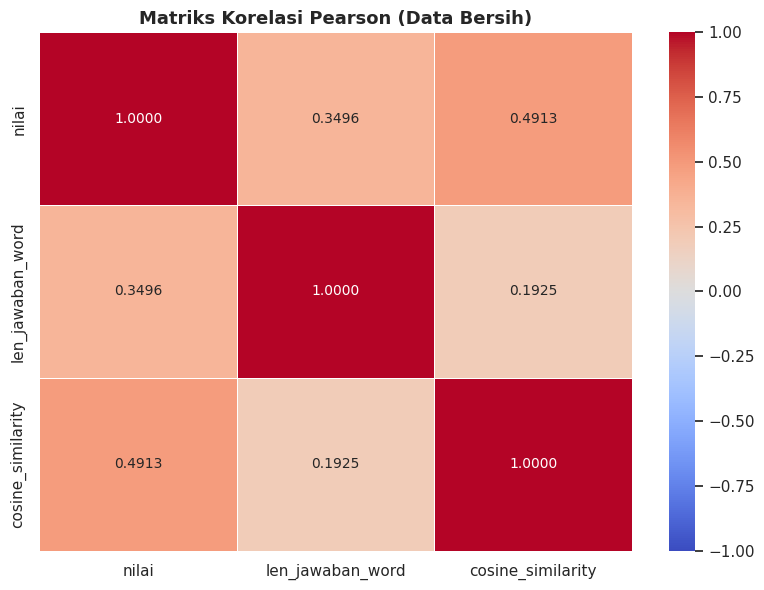

=== NILAI KORELASI PEARSON ===
                      nilai  len_jawaban_word  cosine_similarity
nilai              1.000000          0.349608           0.491309
len_jawaban_word   0.349608          1.000000           0.192508
cosine_similarity  0.491309          0.192508           1.000000


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'df_clean' in globals():
    # Memilih kolom numerik yang relevan
    numeric_cols = ['nilai', 'len_jawaban_word', 'cosine_similarity']
    corr_matrix = df_clean[numeric_cols].corr(method='pearson')

    # Setup plot
    plt.figure(figsize=(8, 6))
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".4f", linewidths=0.5, vmin=-1, vmax=1)
    plt.title('Matriks Korelasi Pearson (Data Bersih)', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Menampilkan interpretasi teks
    print("=== NILAI KORELASI PEARSON ===")
    print(corr_matrix)
else:
    print("[ERROR] Variabel 'df_clean' tidak ditemukan. Pastikan proses pembersihan data sudah dijalankan!")